In [10]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS209_APPLN_IPC,
    TLS224_APPLN_CPC,
)

In [ ]:
from pa_patents import gather_patents

sel = gather_patents()               # config auto-located, or gather_patents("path/to.yaml")
families = sel.families_df()         # pandas, ready for .merge(...)
counts = sel.route_counts_df()

# or join in SQL before pulling anything
sf = sel.selected_families


In [17]:
main_q = (sel.db.query(sf.c.fam_id, TLS201_APPLN.appln_id)
        .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == sf.c.fam_id))
df = sel.patstat.df(main_q) # dont forget to drop_duplicates based on family_id

# Step 1 of the PW: General description of the sector

| Question to answer (Presentation deck, Step 1) | How we measure it in this notebook |
|---|---|
| How big is the field, and is it growing, flat or declining? | Families/patent applications per earliest priority year/appliation year and applications per filing year; growth (%) of the sector compared with the growth (%) of all patents |
| Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass, and by WIPO technology field, over time |
| Where is it happening? | Filing offices (IP5); applicant and inventor countries (fractional counts) |
| Is the field patent-heavy, or does it rely on secrecy? | Compare, for instance, with a similar field |

## 1.1 Sector Definition

Patent extraction is done by using the following routes ( annotated by $R$ ):

$$\text{Precision Agriculture} = \Big[\, R_1 \cup R_2 \cup \big(R_3 \setminus E_{\text{class}}\big) \Big] \setminus \big(E_{\text{topic}} \setminus P\big)$$
- Where: 
$$R_1 = \text{IPC}_{\text{spec}} \cup \text{CPC}_{\text{spec}}$$
$$R_2 = \text{Keywords}_{\text{spec}}$$
$$R_3 = \left(\text{IPC}_{\text{agr}} \cup \text{CPC}_{\text{agr}}\right) \cap \text{Keywords}_{\text{enab}} \cap \text{Keywords}_{\text{PA-func}}$$
$$E_{\text{class}} = \text{CPC}_{\text{excl}} \cup \text{IPC}_{\text{excl}}$$
$$E_{\text{topic}} = \text{Title}_{\text{excl}}$$
$$P = \text{CPC}_{\text{A01B79/005}}$$

<p style="color:red; font-weight:bold;">note: change years in pa_patents! - currently not covering all the years!</p>

In [28]:
OUTPUT_DIR = Path("outputs/step1") # name this how you wish
YEAR_MIN, YEAR_MAX = 2000, 2025
ENV = "PROD" 
SECTOR_NAME = "Precision Agriculture"
# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" earliest priority year (first filing of the invention, anywhere)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models "UM")
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Precision Agriculture | env: PROD | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


**A family (`docdb_family_id`)** - Point of reference chosen by me (Nima)\
At **family level** we need one year per family: we take the **smallest `earliest_filing_year`** among its applications (pw rule) \
These choices are the same for every number in the notebook. State them in the technical appendix of your deck.


## 6. Some other examples to look at

You do not need to understand every line of this section to use the notebook: run it, then read Sections 7–9, where the results are.

### 6.1 Scopes

A **scope** is a query with one row per counting unit (`unit_id`) and its `year`:

- at **family level**, `unit_id` is the `docdb_family_id` and `year` is the family's earliest priority year;
- at **application level**, `unit_id` is the `appln_id` and `year` is its filing year.

We build four scopes, {family, application} × {all patents, sector}. "All patents" is the benchmark: the sector is compared with it. All calculations run inside the database, and only small result tables are downloaded.

In [33]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = sel.db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = sel.db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit

sector_family_ids = sel.db.query(sf.c.fam_id)   
SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_family_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

### 6.2 Counting functions

Each function takes a scope and returns a small `DataFrame` with the columns `scope` and `level`. Counts are in `n` (whole units) or `n_frac` (fractional units).

In [34]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = sel.db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(sel.patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = sel.db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        sel.db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(sel.patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor').

    Each unit is split among its distinct persons with a known country.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks ('  ')
    persons = (
        _join_applications(
            sel.db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = sel.db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        sel.db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(sel.patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(sel.db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            sel.db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        sel.db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        sel.db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(sel.patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            sel.db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(sel.patstat.df(q), scope)


def scope_profile(scope):
    """Number of units, units via PCT, granted units and mean family size (complete years only)."""
    sq = scope.sq
    q = sel.db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(sel.patstat.df(q), scope)

### 6.3 Analysis helpers (pandas)

In [43]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(figsize=(7, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## 7. Volume: how big is the sector, and is it growing?

We count the sector's families and applications per year, and how many of them go through the PCT (international applications). The gap between the two curves is the average number of applications per invention.

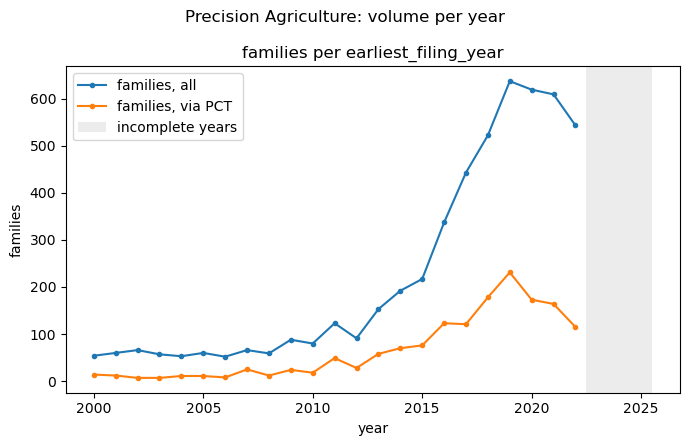

In [58]:
fig, ax = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
data = volume.query("scope == @scope.name and level == @scope.level")
for series, grp in data.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
shade_truncated(ax)
year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
ax.legend()
plt.tight_layout()
plt.show()